Analysis of quality of the rxburn dataset, which we will use as an independent variable in the assessment of California wildfires.

In [1]:
import pandas as pd
from pathlib import Path
import seaborn as sns

In [2]:
#Create raw folder path
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / "data" / "raw"

#Create raw csv file variables
fire25_csv = raw_fldr / "fire_25_TD.csv"
rxburn25_csv = raw_fldr / "rxburn_25_TD.csv"

#Import csv as data frames
fire25_raw = pd.read_csv(fire25_csv)
rxburn_raw = pd.read_csv(rxburn25_csv)


In [ ]:
#Clean imported data, filtering columns and rename
fire25 = fire25_raw.loc[:,['YEAR_', 'd_AGENCY', 'd_UNIT_ID', 'FIRE_NAME', 'INC_NUM', 'ALARM_DATE', 'CONT_DATE', 'GIS_ACRES', 'd_CAUSE', 'd_C_METHOD', 'd_OBJECTIVE', 'COMMENTS']]
rxburn25 = rxburn_raw.loc[:,['YEAR_', 'd_AGENCY', 'd_UNIT_ID', 'd_TREATMENT_TYPE', 'START_DATE', 'END_DATE', 'GIS_ACRES', 'd_PRE_CON_CLASS', 'd_POST_CON_CLASS', 'd_RX_CONSUM', 'TREATMENT_ID']]

fire25['YEAR_'] = fire25['YEAR_'].astype('Int64')
rxburn25['YEAR_'] = rxburn25['YEAR_'].astype('Int64')

fire25 = fire25.rename(
    columns={
        'YEAR_': 'YEAR',
        'd_AGENCY': 'AGENCY',
        'd_UNIT_ID': 'UNIT_ID',
        'd_CAUSE': 'CAUSE',
        'd_OBJECTIVE': 'OBJECTIVE',
        'd_C_METHOD': 'C_METHOD'
    }
)

rxburn25 = rxburn25.rename(
    columns={
        'YEAR_': 'YEAR',
        'd_AGENCY': 'AGENCY',
        'd_UNIT_ID': 'UNIT_ID',
        'd_TREATMENT_TYPE': 'TREATMENT_TYPE',
        'd_PRE_CON_CLASS': 'PRE_CON_CLASS',
        'd_POST_CON_CLASS': 'POST_CON_CLASS',
        'd_RX_CONSUM': 'RX_CONSUM'
    }
)


In [4]:
#check for na values
missing_sum_rx = rxburn25.isna().sum().sort_values(ascending=False)
missing_percents_rx = rxburn25.isna().mean().sort_values(ascending=False) * 100

print(missing_sum_rx)
print(missing_percents_rx)


PRE_CON_CLASS     11472
POST_CON_CLASS    11472
RX_CONSUM         10899
TREATMENT_TYPE     2115
END_DATE           1973
START_DATE         1773
UNIT_ID              48
YEAR                 21
AGENCY                2
GIS_ACRES             2
dtype: int64
PRE_CON_CLASS     95.799582
POST_CON_CLASS    95.799582
RX_CONSUM         91.014614
TREATMENT_TYPE    17.661795
END_DATE          16.475992
START_DATE        14.805846
UNIT_ID            0.400835
YEAR               0.175365
AGENCY             0.016701
GIS_ACRES          0.016701
dtype: float64


Pre and post con classes are missing the most values, followed by the prescribed burn consumption. All other variables had less than 20% of all values missing, which may make them good candidates for analysis. There are more missing values for the categories that are the descriptive values rather than the coded values.

What do we do about the misisng dates? Remove for that specific analysis? Are these the same values that are missing GIS acres? These are our independent variables so they are likely relevant in examining forest fire factors.

In [5]:
#Look at missing dates and missing area of fires
missing_dates = rxburn25.loc[rxburn25['END_DATE'].isna()]
missing_dates_area = missing_dates.loc[missing_dates['GIS_ACRES'].isna()]
print(missing_dates_area)
# There are no values that are missing both spatial and temporal coverage, so likely should not entirely remove these from the data frame

missing_area = rxburn25.loc[rxburn25['GIS_ACRES'].isna()]

Empty DataFrame
Columns: [YEAR, AGENCY, UNIT_ID, TREATMENT_TYPE, START_DATE, END_DATE, GIS_ACRES, PRE_CON_CLASS, POST_CON_CLASS, RX_CONSUM]
Index: []


In [6]:
#check coverage spatially and temporally
print(rxburn25['UNIT_ID'].value_counts())
# important to know the location of the fires so we can compare them to the presence, size, and duration of wild forest fires
# could also look at the agency responsible for the prescribed fires and how successful they are -- how do we manage success?

print(rxburn25['END_DATE'].value_counts())
print(rxburn25['YEAR'].value_counts())
# important to know the date of prescribed burns so we can compare where prescibed impacted following wild forest fires
# will likely have to focus on the 21st century when using prescribed burn data

date2000 = rxburn25.copy()
date2000['YEAR'] = rxburn25['YEAR'].astype(float)
date2000 = date2000.loc[date2000['YEAR'] > 1999]
date2000.isna().mean().sort_values(ascending=False) * 100

UNIT_ID
Klamath National Forest              763
Stanislaus National Forest           748
Lassen National Forest               687
Plumas National Forest               550
Shasta-Trinity National Forest       544
                                    ... 
Empire Mine SHP                        1
Cuyamaca Rancho SP                     1
McArthur-Burney Falls Memorial SP      1
Carl "A" Anderson Redwoods NP          1
Fort Hunter Liggett                    1
Name: count, Length: 145, dtype: int64
END_DATE
9/30/2005 0:00:00     123
11/26/2019 0:00:00     84
12/3/2019 0:00:00      66
2/2/2022 0:00:00       63
1/10/2024 0:00:00      53
                     ... 
6/7/1970 0:00:00        1
10/2/1970 0:00:00       1
12/31/1969 0:00:00      1
8/31/1968 0:00:00       1
9/2/1968 0:00:00        1
Name: count, Length: 3028, dtype: int64
YEAR
2023    1191
2019    1058
2025     982
2024     949
2020     733
        ... 
1914       1
1913       1
1912       1
1911       1
1910       1
Name: count, Length

PRE_CON_CLASS     95.635824
POST_CON_CLASS    95.635824
RX_CONSUM         92.765957
START_DATE        11.024245
TREATMENT_TYPE     4.997526
END_DATE           4.492825
UNIT_ID            0.306779
AGENCY             0.019792
GIS_ACRES          0.019792
YEAR               0.000000
dtype: float64

In [7]:
rxburn25.head()

,YEAR,AGENCY,UNIT_ID,TREATMENT_TYPE,START_DATE,END_DATE,GIS_ACRES,PRE_CON_CLASS,POST_CON_CLASS,RX_CONSUM
0,2025,Bureau of Land Management,Central CA District - BLM,Hand Pile Burn,10/1/2024 0:00:00,2/1/2025 0:00:00,14.621698,NaN,NaN,3 - High Consumption
1,2025,Bureau of Land Management,Northern CA District - BLM,Hand Pile Burn,10/1/2024 0:00:00,2/1/2025 0:00:00,49.999985,NaN,NaN,4 - Very High Consumption
2,2025,Bureau of Land Management,Northern CA District - BLM,Hand Pile Burn,2/10/2025 0:00:00,2/12/2025 0:00:00,228.603134,NaN,NaN,4 - Very High Consumption
3,2025,Bureau of Land Management,Northern CA District - BLM,Hand Pile Burn,10/1/2024 0:00:00,2/13/2025 0:00:00,116.124580,NaN,NaN,4 - Very High Consumption
4,2025,Bureau of Land Management,Central CA District - BLM,Hand Pile Burn,10/1/2024 0:00:00,3/25/2025 0:00:00,25.118351,NaN,NaN,4 - Very High Consumption


In [8]:
#check duplicates
#rxburn25['TREATMENT_ID'].value_counts()


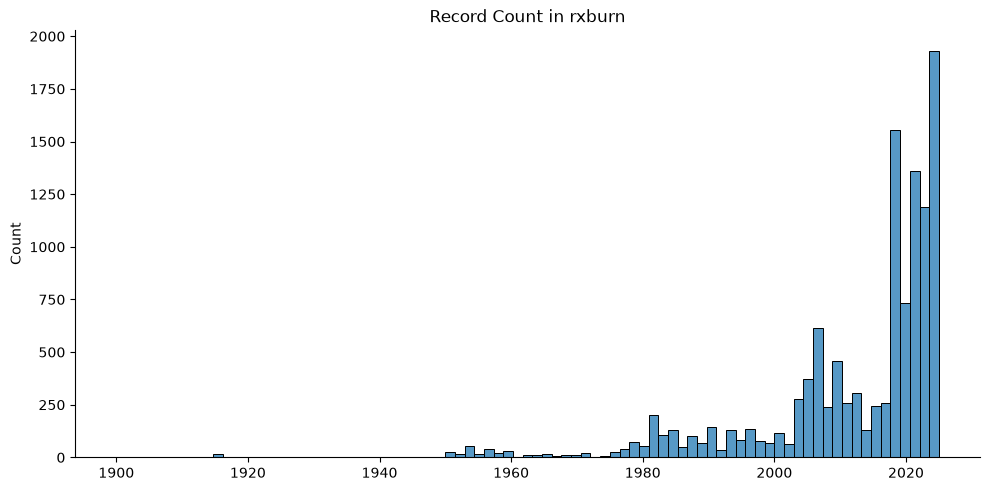

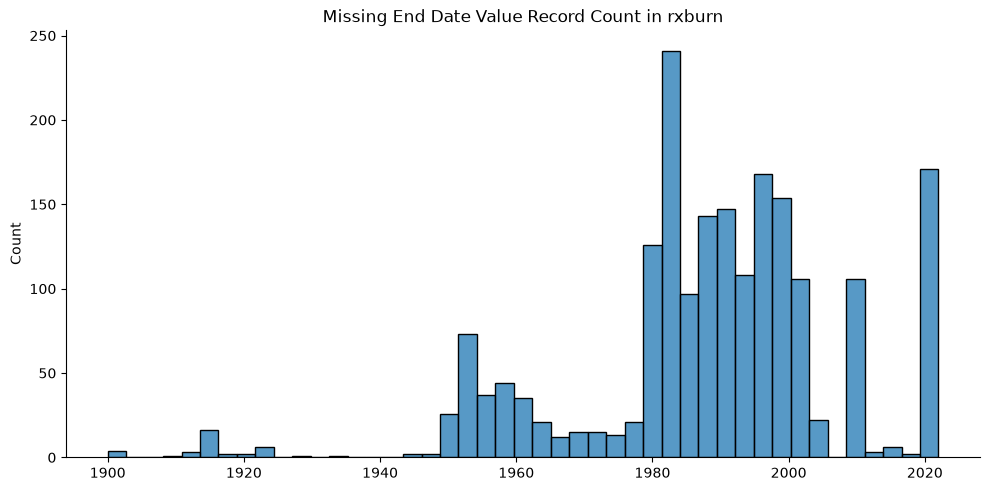

In [14]:
#representative figure
rxburn_date_na = rxburn25.loc[rxburn25['END_DATE'].isna()]

sns.displot(data = rxburn25,
            x = 'YEAR', aspect=2).set(
                xlabel='',
                title='Record Count in rxburn'
            )

sns.displot(data = rxburn_date_na,
            x= 'YEAR', aspect=2).set(
                xlabel='',
                title='Missing End Date Value Record Count in rxburn'
            );

These figures show that there are a lot of dates missing in the years before 2000 compared to the total records. If we want to use the prescribed burn within one year as a point of analysis we need this date data, and so like fire25, it may make sense to limit these data to after 2000.